In [1]:
!pip install -q -r requirements_k.txt
!pip install -q tabula-py
!pip install -q shap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.5/76.5 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.8/857.8 kB 9.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.5/85.5 kB 10.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.4/66.4 kB 7.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.3/68.3 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 33.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 41.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.3/139.3 kB 15.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 75.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.5/162.5 kB 17.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 64.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 31.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━

In [2]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import os
import tabula
import plotly.express as px
import xgboost as xgb


pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
%config Completer.use_jedi = False

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

from sklearn.ensemble import GradientBoostingRegressor


In [3]:
# AE data
ae_data = pd.read_csv('AE_intermediate_data.csv')
ae_data.drop(columns = ['any_ae','sev_fatal', 'sev_life_threatning', 'sev_mild', 'sev_moderate', 'sev_severe','AESER','SAELIFE'],inplace=True)
ae_data.fillna(0,inplace=True)
ae_data.head()

,SUBJID,ae_month,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
0,201001001,month1,1.0,1.0,0.0,1.0,2,1.0,0,1,6.0,6.000000,179.903298,179.903298,2398.710643,2398.710643,399.785107,399.785107,0.0,0.0,399.785107,399.785107,3,0
1,201001001,month2,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
2,201001001,month3,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
3,201001001,>month3,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
4,201001001,month4,11.0,11.0,0.0,0.0,0,1.0,0,0,6.0,65.777778,181.091714,1982.449216,2416.611468,26442.364034,402.430451,4405.475769,0.0,0.0,401.774088,4404.163042,1,0


In [4]:
medhist = pd.read_csv('medical_intermediate.csv')
medhist.head()

,SUBJID,MHANY,MHBNGNYN,MHBODSYS_Dermatologic,MHBODSYS_Endocrine/Metabolic,MHBODSYS_Gastrointestinal,MHBODSYS_Genitourinary/Reproductive,MHBODSYS_Hematologic/Lymphatic,MHBODSYS_Hepatic/Biliary,MHBODSYS_Immunologic,MHBODSYS_Musculoskeletal,MHBODSYS_Neurologic,MHBODSYS_Other,MHBODSYS_Psychiatric,MHBODSYS_Renal,MHBODSYS_Respiratory,MHBODSYS_Special Senses,MHCOND_Benign bone lesions,MHCOND_Benign liver lesions,MHCOND_Benign lung lesions,MHCOND_Benign mediastinal and hilar masses/nodules,MHCOND_Benign renal lesions,MHCOND_Benign retroperitoneal abnormalities,MHCOND_Other,"MHCOND_Post-surgical. -procedural, or -inflammatory fibrosis or scarring",MHCOND_Post-traumatic hematomas,MHSITE_Ascites,MHSITE_Bone,MHSITE_Brain,MHSITE_Breast,MHSITE_Chest wall,MHSITE_Colon,MHSITE_Esophagus,MHSITE_Gall bladder,MHSITE_Kidney,MHSITE_Liver,MHSITE_Lung parenchyma,MHSITE_Lymph Nodes,MHSITE_Other,MHSITE_Pancreas,MHSITE_Pelvis,MHSITE_Pericardial Effusion,MHSITE_Peritoneum,MHSITE_Pleura or pleural wall,MHSITE_Rectum,MHSITE_Skin,MHSITE_Small Intestine,MHSITE_Spinal cord,MHSITE_Spleen,MHSITE_Thyroid,MHSTAT_Resolved
0,201001001,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,201001002,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,201001004,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,201001005,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4,201001006,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [5]:
demobl = pd.read_csv('demography_intermediate2.csv')
demobl.drop(columns = ['STUDYID','SITEID','SEXCD','RACCATCD','TRTFRQCD','TRTCD','TRT','TRTFREQ','ATRTCD',\
                      'PRBEVCDR','PRBEVCDM','PROXACDR','PROXACDM','PROXALCD','LIVRONCD','PADJYNCD',\
                       'BECOGICD','DIAGTYCD','TUMCATCD','KRASCD','B_ECOGCD','HISTYPCD','HISSBTCD','HDIFFCD','BIOPPNO',\
                      'BIOPPFCD','BIOPHFCD','BIOPBSCD','BIOPEFCD','BIOPPCCD','BIOPCYCD','PREGTYCD','PREGRSCD','BIORSNCD'],inplace=True)
for col in demobl.columns:
    demobl[col].replace({True:1,False:0,'N':0,'Y':1,'Positive':1,'Negative':0},inplace=True)
    demobl[col].fillna(0,inplace=True)
demobl.head(5)

,Unnamed: 0,SUBJID,AGE,TRTDOSE,PRBEVR,PRBEVM,PRBEVCD,PROXAR,PROXAM,B_METANM,LIVRONLY,PRADJYN,DPADJUV,B_LDHYN,B_LDH2YN,B_LDHNM,TUMCAT,LIVERMET,EVALITT,EVALPP,EVALQOL,EVALEGFR,TRTDUR,B_WEIGHT,B_HEIGHT,B_BSA,DIAGMONS,METMONS,BIOPACPT,BIOPF,BIOPHACT,BIOPHF,BIOPSTCD,BIOPTPCT,BIOPRSCD,BIOPRS,BIOPEF,BIOPNEG,BIOPWEAK,BIOPMOD,BIOPSTRG,BIOP3,BIOPS123,BIOPCYTO,H11NEG,H11WEAK,H11MOD,UGT1A1YN,CHILDPOT,PREGDONE,BIONANY,diagdy,metdxdy,biopdy,biopdy2,PREGDY,HDIFFER_Poorly differentiated,HDIFFER_Undifferentiated,HDIFFER_Unknown,HDIFFER_Well differentiated,HISSUBTY_Mucinous,HISSUBTY_No sub-type,HISSUBTY_Other,HISSUBTY_Unknown,BIOPNO_100-500 cells present,BIOPNO_50-99 cells present,BIOPNO_>500 cells present,BIOPPCT_<10%,BIOPPCT_>35%,BIOPCY_<10%,BIOPCY_>35%,BIOPMAX_1+,BIOPMAX_2+,BIOPMAX_3+,BIOPSITE_Primary,B_ECOG_In bed,B_ECOG_Symptoms but ambulatory,PREGRES_Not applicable,SEX_Female,SEX_Male,RACCAT_Other,RACCAT_White or Caucasian,ATRT_FOLFIRI alone,ATRT_Panitumumab + FOLFIRI,PRBEV_N,PRBEV_Y,PROXAL_N,PROXAL_Y,B_METACT_1,B_METACT_2,B_METACT_>=3,B_ECOGI_Fully active,B_ECOGI_In bed less than 50% of the time,B_ECOGI_Symptoms but ambulatory,BECGICT_0 or 1,BECGICT_2,DIAGTYPE_Colon,DIAGTYPE_Rectal,KRAS_Failed,KRAS_Mutant,KRAS_Wild-type,BIOPMAXC_0,BIOPMAXC_1+,BIOPMAXC_2+,BIOPMAXC_3+,BIOPBSIT_Anus,BIOPBSIT_Bone,BIOPBSIT_Breast,BIOPBSIT_Colon,BIOPBSIT_Liver,BIOPBSIT_Lung parenchyma,BIOPBSIT_Lymph Nodes,BIOPBSIT_Other,BIOPBSIT_Peritoneum,BIOPBSIT_Pleural effusion,BIOPBSIT_Rectum,BIOPBSIT_Small Intestine,BIOPBSIT_Stomach,PREGTYPE_Pregnancy - Serum,PREGTYPE_Pregnancy - Urine
0,0,201001001,54.0,6.0,1,1,1.0,1,1,4.0,0,0,0.0,0.0,0.0,187.0,1,1,1,1,1,1,219.0,80.0,182.0,2.011080,9.540984,9.540984,1.0,0,1.0,0,1.0,61.28,1.0,1,0,85.3,9.8,5.0,0.0,0.0,14.8,2.1,97.9,2.1,0.0,0.0,0.0,0.0,0.0,-293.0,-293.0,644.0,667.0,0.0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1,201001002,66.0,6.0,1,1,1.0,1,1,3.0,0,0,0.0,0.0,0.0,215.0,1,1,1,1,1,1,60.0,93.0,178.0,2.144372,6.131148,6.131148,1.0,0,1.0,0,1.0,43.22,1.0,1,0,99.9,0.1,0.0,0.0,0.0,0.1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,-193.0,-193.0,670.0,698.0,0.0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2,201001004,58.0,6.0,0,0,0.0,1,1,3.0,0,0,0.0,1.0,0.0,392.0,0,1,1,1,1,1,437.0,62.0,164.0,1.680608,12.327869,12.852459,1.0,0,1.0,0,1.0,46.74,2.0,0,0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,-381.0,-397.0,554.0,571.0,0.0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,1,1,0,0,1,0,0,1,1,0,0,1,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,3,201001005,75.0,6.0,1,1,1.0,1,1,2.0,0,0,0.0,0.0,0.0,267.0,1,1,1,1,1,1,220.0,106.0,188.0,2.352776,9.803279,9.803279,1.0,0,1.0,0,1.0,23.90,1.0,1,0,96.3,3.8,0.0,0.0,0.0,3.8,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,-306.0,-306.0,589.0,616.0,0.0,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,1,0,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,4,201001006,52.0,0.0,1,1,1.0,1,1,3.0,0,0,0.0,1.0,1.0,572.0,1,1,1,1,0,1,3.0,130.0,200.0,2.687419,2.885246,3.540984,1.0,0,1.0,0,1.0,42.19,1.0,1,0,95.3,4.5,0.2,0.0,0.0,4.7,5.1,94.9,5.1,0.0,0.0,0.0,0.0,0.0,-89.0,-109.0,518.0,535.0,0.0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,0,0,1,0,1,0,1,1,0,1,0,1,1,0,0,1,0,1,0,0,1,0,0,1,1,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
ae_data

,SUBJID,ae_month,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
0,201001001,month1,1.0,1.0,0.0,1.0,2,1.0,0,1,6.0,6.000000,179.903298,179.903298,2398.710643,2398.710643,399.785107,399.785107,0.0,0.0,399.785107,399.785107,3,0
1,201001001,month2,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
2,201001001,month3,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
3,201001001,>month3,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
4,201001001,month4,11.0,11.0,0.0,0.0,0,1.0,0,0,6.0,65.777778,181.091714,1982.449216,2416.611468,26442.364034,402.430451,4405.475769,0.0,0.0,401.774088,4404.163042,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7395,203908001,>month3,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
7396,203908001,month4,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
7397,203908001,month5,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
7398,203908001,month6,0.0,0.0,0.0,0.0,0,0.0,0,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0


# Month1 prediction

In [7]:
m1_ae = ae_data[ae_data['ae_month'] == 'month1'].copy()
m1_ae.drop(columns=['ae_month',],inplace=True)
m1_ae.head()

,SUBJID,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
0,201001001,1.0,1.0,0.0,1.0,2,1.0,0,1,6.000000,6.000000,179.903298,179.903298,2398.710643,2398.710643,399.785107,399.785107,0.0,0.0,399.785107,399.785107,3,0
8,201001002,3.0,3.0,0.0,0.0,2,0.0,0,2,6.000000,18.000000,177.226673,531.680019,2363.036295,7089.108884,393.840160,1181.520479,0.0,0.0,393.840160,1181.268657,2,0
16,201001004,0.0,0.0,0.0,0.0,0,0.0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0,0
24,201001005,2.0,3.0,0.0,0.0,3,1.0,0,3,6.174757,12.174757,178.053774,535.964568,2375.775023,7144.836609,395.672179,1191.018084,0.0,0.0,394.956429,1189.905652,4,0
32,201001006,0.0,1.0,0.0,0.0,0,1.0,0,1,0.000000,0.000000,133.957513,133.957513,1786.100178,1786.100178,297.683363,297.683363,0.0,0.0,297.683363,297.683363,1,0


In [8]:
ID = 'SUBJID'
TARGET = 'total_AE'
other_Cols = ['total_SAE']


In [9]:
fin_df = pd.merge(demobl,medhist,on=['SUBJID'],how='left')
fin_df = pd.merge(fin_df,m1_ae,on=['SUBJID'],how='inner')
fin_df.columns = fin_df.columns.str.replace(" ", "_")
fin_df.columns = fin_df.columns.str.replace("<", "lessthan")
fin_df.drop(columns=['BIOPF', 'BIOPHF', 'BIOPRS', 'BIOPEF'],inplace=True)

fin_df.head()

,Unnamed:_0,SUBJID,AGE,TRTDOSE,PRBEVR,PRBEVM,PRBEVCD,PROXAR,PROXAM,B_METANM,LIVRONLY,PRADJYN,DPADJUV,B_LDHYN,B_LDH2YN,B_LDHNM,TUMCAT,LIVERMET,EVALITT,EVALPP,EVALQOL,EVALEGFR,TRTDUR,B_WEIGHT,B_HEIGHT,B_BSA,DIAGMONS,METMONS,BIOPACPT,BIOPHACT,BIOPSTCD,BIOPTPCT,BIOPRSCD,BIOPNEG,BIOPWEAK,BIOPMOD,BIOPSTRG,BIOP3,BIOPS123,BIOPCYTO,H11NEG,H11WEAK,H11MOD,UGT1A1YN,CHILDPOT,PREGDONE,BIONANY,diagdy,metdxdy,biopdy,biopdy2,PREGDY,HDIFFER_Poorly_differentiated,HDIFFER_Undifferentiated,HDIFFER_Unknown,HDIFFER_Well_differentiated,HISSUBTY_Mucinous,HISSUBTY_No_sub-type,HISSUBTY_Other,HISSUBTY_Unknown,BIOPNO_100-500_cells_present,BIOPNO_50-99_cells_present,BIOPNO_>500_cells_present,BIOPPCT_lessthan10%,BIOPPCT_>35%,BIOPCY_lessthan10%,BIOPCY_>35%,BIOPMAX_1+,BIOPMAX_2+,BIOPMAX_3+,BIOPSITE_Primary,B_ECOG_In_bed,B_ECOG_Symptoms_but_ambulatory,PREGRES_Not_applicable,SEX_Female,SEX_Male,RACCAT_Other,RACCAT_White_or_Caucasian,ATRT_FOLFIRI_alone,ATRT_Panitumumab_+_FOLFIRI,PRBEV_N,PRBEV_Y,PROXAL_N,PROXAL_Y,B_METACT_1,B_METACT_2,B_METACT_>=3,B_ECOGI_Fully_active,B_ECOGI_In_bed_less_than_50%_of_the_time,B_ECOGI_Symptoms_but_ambulatory,BECGICT_0_or_1,BECGICT_2,DIAGTYPE_Colon,DIAGTYPE_Rectal,KRAS_Failed,KRAS_Mutant,KRAS_Wild-type,BIOPMAXC_0,BIOPMAXC_1+,BIOPMAXC_2+,BIOPMAXC_3+,BIOPBSIT_Anus,BIOPBSIT_Bone,BIOPBSIT_Breast,BIOPBSIT_Colon,BIOPBSIT_Liver,BIOPBSIT_Lung_parenchyma,BIOPBSIT_Lymph_Nodes,BIOPBSIT_Other,BIOPBSIT_Peritoneum,BIOPBSIT_Pleural_effusion,BIOPBSIT_Rectum,BIOPBSIT_Small_Intestine,BIOPBSIT_Stomach,PREGTYPE_Pregnancy_-_Serum,PREGTYPE_Pregnancy_-_Urine,MHANY,MHBNGNYN,MHBODSYS_Dermatologic,MHBODSYS_Endocrine/Metabolic,MHBODSYS_Gastrointestinal,MHBODSYS_Genitourinary/Reproductive,MHBODSYS_Hematologic/Lymphatic,MHBODSYS_Hepatic/Biliary,MHBODSYS_Immunologic,MHBODSYS_Musculoskeletal,MHBODSYS_Neurologic,MHBODSYS_Other,MHBODSYS_Psychiatric,MHBODSYS_Renal,MHBODSYS_Respiratory,MHBODSYS_Special_Senses,MHCOND_Benign_bone_lesions,MHCOND_Benign_liver_lesions,MHCOND_Benign_lung_lesions,MHCOND_Benign_mediastinal_and_hilar_masses/nodules,MHCOND_Benign_renal_lesions,MHCOND_Benign_retroperitoneal_abnormalities,MHCOND_Other,"MHCOND_Post-surgical._-procedural,_or_-inflammatory_fibrosis_or_scarring",MHCOND_Post-traumatic_hematomas,MHSITE_Ascites,MHSITE_Bone,MHSITE_Brain,MHSITE_Breast,MHSITE_Chest_wall,MHSITE_Colon,MHSITE_Esophagus,MHSITE_Gall_bladder,MHSITE_Kidney,MHSITE_Liver,MHSITE_Lung_parenchyma,MHSITE_Lymph_Nodes,MHSITE_Other,MHSITE_Pancreas,MHSITE_Pelvis,MHSITE_Pericardial_Effusion,MHSITE_Peritoneum,MHSITE_Pleura_or_pleural_wall,MHSITE_Rectum,MHSITE_Skin,MHSITE_Small_Intestine,MHSITE_Spinal_cord,MHSITE_Spleen,MHSITE_Thyroid,MHSTAT_Resolved,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
0,0,201001001,54.0,6.0,1,1,1.0,1,1,4.0,0,0,0.0,0.0,0.0,187.0,1,1,1,1,1,1,219.0,80.0,182.0,2.011080,9.540984,9.540984,1.0,1.0,1.0,61.28,1.0,85.3,9.8,5.0,0.0,0.0,14.8,2.1,97.9,2.1,0.0,0.0,0.0,0.0,0.0,-293.0,-293.0,644.0,667.0,0.0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,1.0,0.0,1.0,2,1.0,0,1,6.000000,6.000000,179.903298,179.903298,2398.710643,2398.710643,399.785107,399.785107,0.0,0.0,399.785107,399.785107,3,0
1,1,201001002,66.0,6.0,1,1,1.0,1,1,3.0,0,0,0.0,0.0,0.0,215.0,1,1,1,1,1,1,60.0,93.0,178.0,2.144372,6.131148,6.131148,1.0,1.0,1.0,43.22,1.0,99.9,0.1,0.0,0.0,0.0,0.1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,-193.0,-193.0,670.0,698.0,0.0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3.0,3.0,0.0,0.0,2,0.0,0,2,6.000000,18.000000,177.226673,531.680019,2

In [10]:
fin_df.drop(columns=['Unnamed:_0'],inplace=True)

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

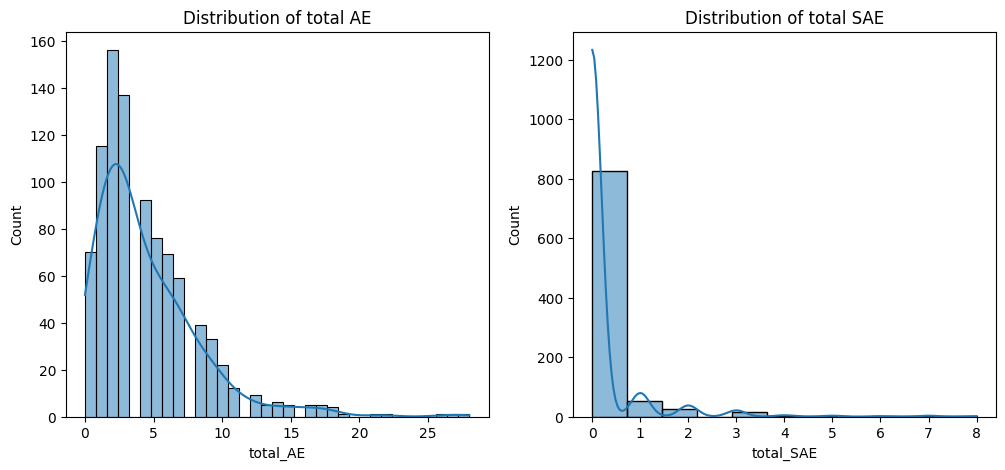

In [12]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(fin_df['total_AE'], kde=True)
plt.title('Distribution of total AE')
plt.subplot(1, 2, 2)
sns.histplot(fin_df['total_SAE'], kde=True)
plt.title('Distribution of total SAE')
plt.show()

In [13]:
X = fin_df.drop(['total_AE', 'total_SAE'], axis=1)
y_ae = fin_df['total_AE']
y_sae = fin_df['total_SAE']

In [14]:
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [15]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [16]:
X_scaled

,SUBJID,AGE,TRTDOSE,PRBEVR,PRBEVM,PRBEVCD,PROXAR,PROXAM,B_METANM,LIVRONLY,PRADJYN,DPADJUV,B_LDHYN,B_LDH2YN,B_LDHNM,TUMCAT,LIVERMET,EVALITT,EVALPP,EVALQOL,EVALEGFR,TRTDUR,B_WEIGHT,B_HEIGHT,B_BSA,DIAGMONS,METMONS,BIOPACPT,BIOPHACT,BIOPSTCD,BIOPTPCT,BIOPRSCD,BIOPNEG,BIOPWEAK,BIOPMOD,BIOPSTRG,BIOP3,BIOPS123,BIOPCYTO,H11NEG,H11WEAK,H11MOD,UGT1A1YN,CHILDPOT,PREGDONE,BIONANY,diagdy,metdxdy,biopdy,biopdy2,PREGDY,HDIFFER_Poorly_differentiated,HDIFFER_Undifferentiated,HDIFFER_Unknown,HDIFFER_Well_differentiated,HISSUBTY_Mucinous,HISSUBTY_No_sub-type,HISSUBTY_Other,HISSUBTY_Unknown,BIOPNO_100-500_cells_present,BIOPNO_50-99_cells_present,BIOPNO_>500_cells_present,BIOPPCT_lessthan10%,BIOPPCT_>35%,BIOPCY_lessthan10%,BIOPCY_>35%,BIOPMAX_1+,BIOPMAX_2+,BIOPMAX_3+,BIOPSITE_Primary,B_ECOG_In_bed,B_ECOG_Symptoms_but_ambulatory,PREGRES_Not_applicable,SEX_Female,SEX_Male,RACCAT_Other,RACCAT_White_or_Caucasian,ATRT_FOLFIRI_alone,ATRT_Panitumumab_+_FOLFIRI,PRBEV_N,PRBEV_Y,PROXAL_N,PROXAL_Y,B_METACT_1,B_METACT_2,B_METACT_>=3,B_ECOGI_Fully_active,B_ECOGI_In_bed_less_than_50%_of_the_time,B_ECOGI_Symptoms_but_ambulatory,BECGICT_0_or_1,BECGICT_2,DIAGTYPE_Colon,DIAGTYPE_Rectal,KRAS_Failed,KRAS_Mutant,KRAS_Wild-type,BIOPMAXC_0,BIOPMAXC_1+,BIOPMAXC_2+,BIOPMAXC_3+,BIOPBSIT_Anus,BIOPBSIT_Bone,BIOPBSIT_Breast,BIOPBSIT_Colon,BIOPBSIT_Liver,BIOPBSIT_Lung_parenchyma,BIOPBSIT_Lymph_Nodes,BIOPBSIT_Other,BIOPBSIT_Peritoneum,BIOPBSIT_Pleural_effusion,BIOPBSIT_Rectum,BIOPBSIT_Small_Intestine,BIOPBSIT_Stomach,PREGTYPE_Pregnancy_-_Serum,PREGTYPE_Pregnancy_-_Urine,MHANY,MHBNGNYN,MHBODSYS_Dermatologic,MHBODSYS_Endocrine/Metabolic,MHBODSYS_Gastrointestinal,MHBODSYS_Genitourinary/Reproductive,MHBODSYS_Hematologic/Lymphatic,MHBODSYS_Hepatic/Biliary,MHBODSYS_Immunologic,MHBODSYS_Musculoskeletal,MHBODSYS_Neurologic,MHBODSYS_Other,MHBODSYS_Psychiatric,MHBODSYS_Renal,MHBODSYS_Respiratory,MHBODSYS_Special_Senses,MHCOND_Benign_bone_lesions,MHCOND_Benign_liver_lesions,MHCOND_Benign_lung_lesions,MHCOND_Benign_mediastinal_and_hilar_masses/nodules,MHCOND_Benign_renal_lesions,MHCOND_Benign_retroperitoneal_abnormalities,MHCOND_Other,"MHCOND_Post-surgical._-procedural,_or_-inflammatory_fibrosis_or_scarring",MHCOND_Post-traumatic_hematomas,MHSITE_Ascites,MHSITE_Bone,MHSITE_Brain,MHSITE_Breast,MHSITE_Chest_wall,MHSITE_Colon,MHSITE_Esophagus,MHSITE_Gall_bladder,MHSITE_Kidney,MHSITE_Liver,MHSITE_Lung_parenchyma,MHSITE_Lymph_Nodes,MHSITE_Other,MHSITE_Pancreas,MHSITE_Pelvis,MHSITE_Pericardial_Effusion,MHSITE_Peritoneum,MHSITE_Pleura_or_pleural_wall,MHSITE_Rectum,MHSITE_Skin,MHSITE_Small_Intestine,MHSITE_Spinal_cord,MHSITE_Spleen,MHSITE_Thyroid,MHSTAT_Resolved,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS
0,-1.272432,-0.633265,0.986043,2.358025,2.348209,2.300547,0.729011,0.715149,1.233199,-0.452136,-0.486447,-0.367382,-0.658869,-0.489843,-0.145335,0.762362,0.402567,0.0,0.258645,0.350104,0.660557,0.390127,0.398275,1.196961,0.703442,-0.394547,-0.066131,0.496619,0.563617,-0.176678,1.118181,-0.062744,0.486639,0.489849,0.700238,-0.113559,-0.236508,0.540768,0.042182,0.659121,0.112623,-0.100668,-0.046549,-0.2208,-0.228762,-0.109704,0.393118,0.062241,1.087010,1.098596,0.113529,-0.420529,-0.065902,-0.305582,-0.384243,-0.330322,1.176444,-0.371162,-0.748241,-0.452136,-0.179906,0.913957,-1.118306,-0.239046,0.727273,-0.104542,-0.734235,2.627924,-0.236508,0.371162,-0.256258,-0.967030,0.263371,-0.823872,0.823872,-0.093403,0.093403,-0.988178,0.988178,-2.300547,2.300547,-0.663935,0.663935,-0.496619,-0.685994,1.047619,1.052170,-0.228762,-0.952479,0.228762,-0.228762,0.762362,-0.762362,-0.170062,1.219245,-1.011963,-0.952479,2.146173,-0.192342,-0.080801,-0.046549,-0.046549,-0.032898,-0.046549,-0.22348,-0.065902,-0.046549,-0.119392,-0.087323,-0.032898,-0.065902,-0.046549,-0.046549,-0.13683,-0.179906,-2.794553,-0.531921,-0.26571,-0.530248,-0.822025,-0.615256,-0

In [17]:
# For total_AE
rf_ae = RandomForestRegressor(n_estimators=100,max_depth= 5, random_state=42)
rf_ae.fit(X_scaled, y_ae)
feature_importance_ae = pd.DataFrame({'feature': X.columns, 'importance': rf_ae.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)

# For total_SAE
rf_sae = RandomForestRegressor(n_estimators=100,max_depth= 5,random_state=42)
rf_sae.fit(X_scaled, y_sae)
feature_importance_sae = pd.DataFrame({'feature': X.columns, 'importance': rf_sae.feature_importances_})
feature_importance_sae = feature_importance_sae.sort_values('importance', ascending=False)

print("Top features for total_AE:")
print(feature_importance_ae.head(30))
print("\nTop features for total_SAE:")
print(feature_importance_sae.head(30))

Top features for total_AE:
                   feature  importance
170                AERELCM    0.562623
172                AEACT03    0.333475
169                  AEREL    0.022354
180               AEFBCDOS    0.007805
178               AEFICDOS    0.006290
175               AEIRWDOS    0.005046
0                   SUBJID    0.004449
179               AEFBWDOS    0.003739
21                  TRTDUR    0.003352
177               AEFIWDOS    0.003209
176               AEIRCDOS    0.003206
23                B_HEIGHT    0.003092
14                 B_LDHNM    0.002775
8                 B_METANM    0.002646
166     prior_chemo_cycles    0.002642
1                      AGE    0.002557
24                   B_BSA    0.002101
25                DIAGMONS    0.002098
49                 biopdy2    0.001430
46                  diagdy    0.001388
30                BIOPTPCT    0.001306
174                 AECDOS    0.001238
183               AEDLWDOS    0.001058
48                  biopdy    0.00091

In [18]:
top_features_ae = feature_importance_ae['feature'][:30].tolist()
top_features_sae = feature_importance_sae['feature'][:30].tolist()

In [19]:
X_ae = X_scaled[top_features_ae]
X_sae = X_scaled[top_features_sae]
# Split the data into train, validation, and test sets
X_train, X_temp, y_ae_train, y_ae_temp = train_test_split(X_ae, y_ae, test_size=0.33, random_state=42)
X_val, X_test, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.3, random_state=42)

X_train, X_temp, y_sae_train, y_sae_temp = train_test_split(X_sae, y_sae, test_size=0.33, random_state=42)
X_val, X_test, y_sae_val, y_sae_test = train_test_split(X_temp, y_sae_temp, test_size=0.3, random_state=42)

In [20]:
def evaluate_and_plot(y_true, y_pred, model_name, target):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{model_name} RMSE for {target}: {rmse}")

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, y_pred, alpha=0.5)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2)
    plt.xlabel('True Values')
    plt.ylabel('Predicted Values')
    plt.title(f"{model_name} - {target} - True vs Predicted")
    plt.show()

def train_and_evaluate(model, X_train, y_train, X_val, y_val, X_test, y_test, model_name, target):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    evaluate_and_plot(y_test, y_pred, model_name, target)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_score = np.sqrt(mean_squared_error(y_train, train_pred))
    test_score =  np.sqrt(mean_squared_error(y_test, test_pred))

    print(f"{model_name} Training RMSE: {train_score}")
    print(f"{model_name} Test RMSE: {test_score}")

    # Create DataFrame with actual and predicted values
    comparison_df = pd.DataFrame({
        'Actual': y_test,
        'Predicted': y_pred
    })

    return model, comparison_df, train_score, test_score


In [21]:
# from sklearn.model_selection import RandomizedSearchCV
# from scipy.stats import uniform, randint

# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train, y_ae_train)

# best_params = random_search.best_params_
# best_model = random_search.best_estimator_

XGBoost RMSE for AE: 1.6470034495787107


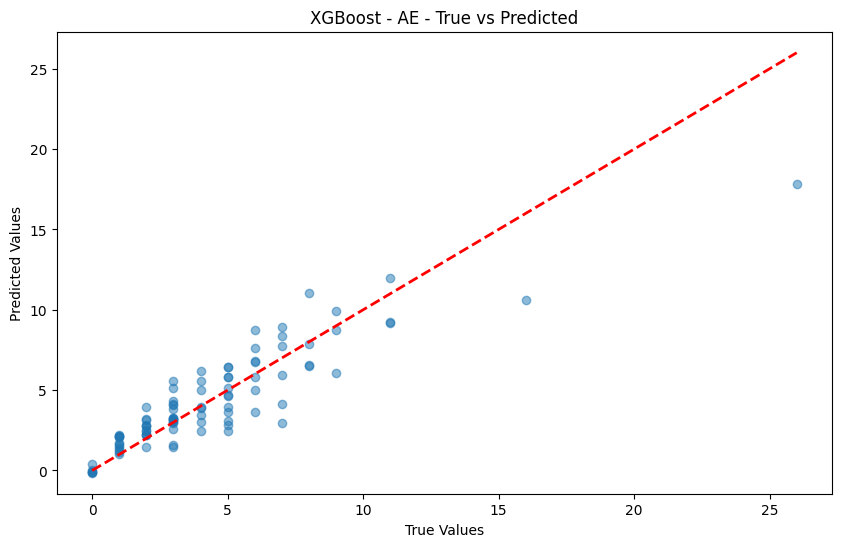

XGBoost Training RMSE: 0.7244149716096295
XGBoost Test RMSE: 1.6470034495787107
XGBoost RMSE for SAE: 0.4620065490076549


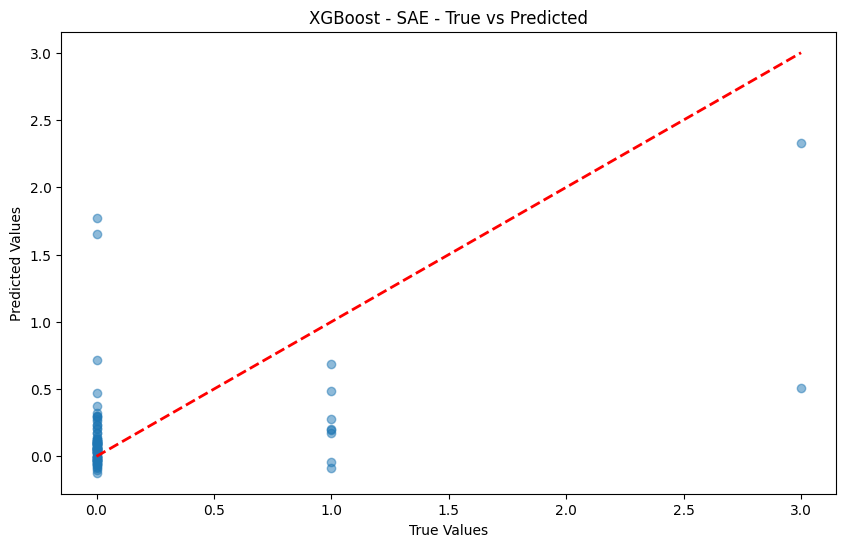

XGBoost Training RMSE: 0.1995763434590875
XGBoost Test RMSE: 0.4620065490076549


In [22]:
# XGBoost
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=280,
        learning_rate=0.05,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.96,
        colsample_bytree=0.729,
        gamma=0
    ),
    X_train, y_ae_train, X_val, y_ae_val, X_test, y_ae_test, "XGBoost", "AE"
)

xgb_sae, xgb_sae_comparison, train_sae_mse, test_sae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=280,
        learning_rate=0.05,
        eta=0.1,
        max_depth=3,
        random_state=42,
        eval_metric='rmse',
        subsample=0.96,
        colsample_bytree=0.729,
        gamma=0
    ),
    X_train, y_sae_train, X_val, y_sae_val, X_test, y_sae_test, "XGBoost", "SAE"
)

In [23]:
#for AE
xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
xgb_sae_comparison['Predicted'] = np.round(xgb_sae_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)
print("")
#for SAE
compdf_xgb_sae= pd.DataFrame({'actual_SAE': xgb_sae_comparison['Actual'].values, 'predicted_SAE': [round(i) for i in xgb_sae_comparison['Predicted']]})
diff_xgb_sae = abs(compdf_xgb_sae['actual_SAE']-compdf_xgb_sae['predicted_SAE'])
print("sum of absolute diff between predicted and actual SAE: ",diff_xgb_sae.sum())
print("max value abs diff in SAE: ",max(diff_xgb_sae))
average_deviation_sae = sum(diff_xgb_sae) / len(diff_xgb_sae)
print("average deviation in predicted and actual SAE: ",average_deviation_sae)

sum of absolute diff between predicted and actual AE:  100
max value abs diff in AE:  8
average deviation in predicted and actual AE:  1.0869565217391304

sum of absolute diff between predicted and actual SAE:  15
max value abs diff in SAE:  2
average deviation in predicted and actual SAE:  0.16304347826086957


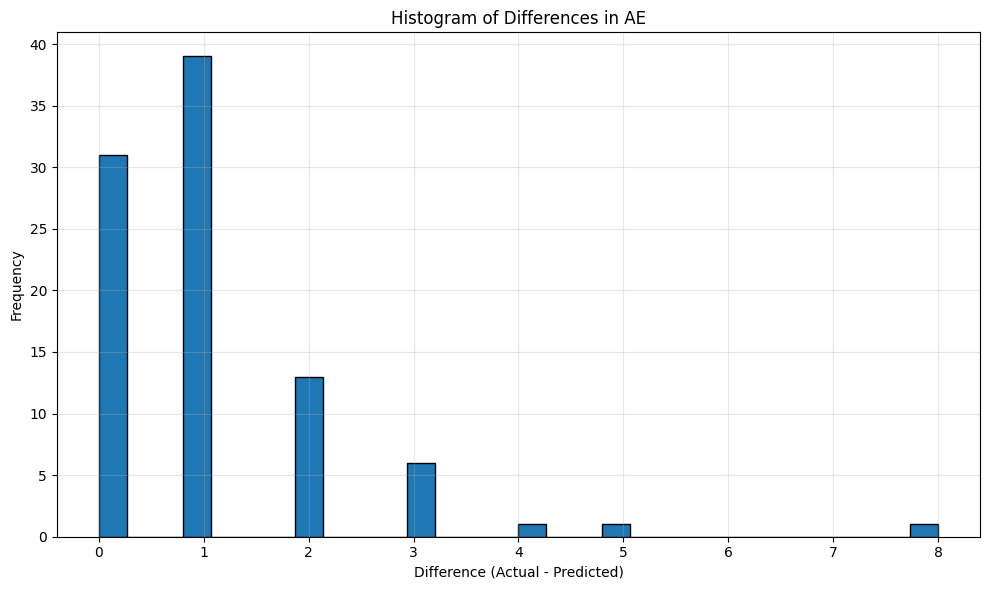

In [25]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

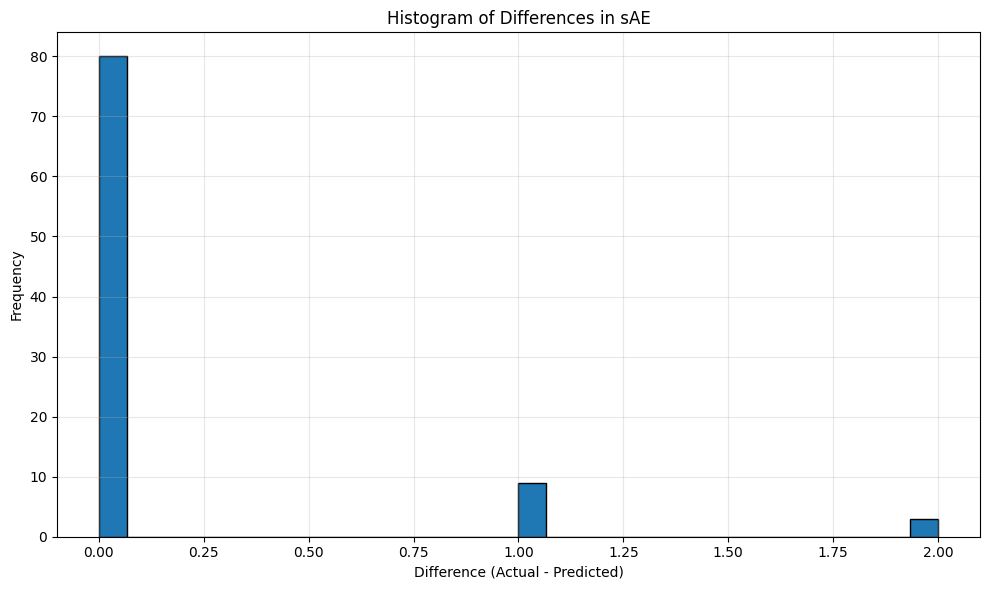

In [26]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb_sae, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in sAE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Month 2

we will also include month_1 AE as a feature for predicting values in next month.

In [27]:
m2_ae = ae_data[ae_data['ae_month'] == 'month2'].copy()
m2_ae.drop(columns=['ae_month',],inplace=True)
m2_ae.head()

,SUBJID,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
1,201001001,0.0,0.0,0.0,0.0,0,0.0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0,0
9,201001002,0.0,0.0,0.0,0.0,0,0.0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0,0
17,201001004,4.0,4.0,0.0,0.0,0,1.0,0,0,6.305085,24.403445,183.867174,723.422254,2452.050293,9647.549966,408.595754,1607.613009,0.0,0.0,407.455123,1404.38766,2,0
25,201001005,3.0,4.0,0.0,0.0,0,1.0,0,0,6.174757,18.349515,178.053774,714.018343,2375.775023,9520.611632,395.672179,1586.690263,0.0,0.0,394.956429,1584.86208,1,0
33,201001006,0.0,0.0,0.0,0.0,0,0.0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0,0


In [28]:
fin_df2 = pd.merge(demobl,medhist,on=['SUBJID'],how='left')
fin_df2 = pd.merge(fin_df2,m2_ae,on=['SUBJID'],how='inner')
fin_df2.columns = fin_df2.columns.str.replace(" ", "_")
fin_df2.columns = fin_df2.columns.str.replace("<", "lessthan")
fin_df2.drop(columns=['BIOPF', 'BIOPHF', 'BIOPRS', 'BIOPEF'],inplace=True)

fin_df2.head()

,Unnamed:_0,SUBJID,AGE,TRTDOSE,PRBEVR,PRBEVM,PRBEVCD,PROXAR,PROXAM,B_METANM,LIVRONLY,PRADJYN,DPADJUV,B_LDHYN,B_LDH2YN,B_LDHNM,TUMCAT,LIVERMET,EVALITT,EVALPP,EVALQOL,EVALEGFR,TRTDUR,B_WEIGHT,B_HEIGHT,B_BSA,DIAGMONS,METMONS,BIOPACPT,BIOPHACT,BIOPSTCD,BIOPTPCT,BIOPRSCD,BIOPNEG,BIOPWEAK,BIOPMOD,BIOPSTRG,BIOP3,BIOPS123,BIOPCYTO,H11NEG,H11WEAK,H11MOD,UGT1A1YN,CHILDPOT,PREGDONE,BIONANY,diagdy,metdxdy,biopdy,biopdy2,PREGDY,HDIFFER_Poorly_differentiated,HDIFFER_Undifferentiated,HDIFFER_Unknown,HDIFFER_Well_differentiated,HISSUBTY_Mucinous,HISSUBTY_No_sub-type,HISSUBTY_Other,HISSUBTY_Unknown,BIOPNO_100-500_cells_present,BIOPNO_50-99_cells_present,BIOPNO_>500_cells_present,BIOPPCT_lessthan10%,BIOPPCT_>35%,BIOPCY_lessthan10%,BIOPCY_>35%,BIOPMAX_1+,BIOPMAX_2+,BIOPMAX_3+,BIOPSITE_Primary,B_ECOG_In_bed,B_ECOG_Symptoms_but_ambulatory,PREGRES_Not_applicable,SEX_Female,SEX_Male,RACCAT_Other,RACCAT_White_or_Caucasian,ATRT_FOLFIRI_alone,ATRT_Panitumumab_+_FOLFIRI,PRBEV_N,PRBEV_Y,PROXAL_N,PROXAL_Y,B_METACT_1,B_METACT_2,B_METACT_>=3,B_ECOGI_Fully_active,B_ECOGI_In_bed_less_than_50%_of_the_time,B_ECOGI_Symptoms_but_ambulatory,BECGICT_0_or_1,BECGICT_2,DIAGTYPE_Colon,DIAGTYPE_Rectal,KRAS_Failed,KRAS_Mutant,KRAS_Wild-type,BIOPMAXC_0,BIOPMAXC_1+,BIOPMAXC_2+,BIOPMAXC_3+,BIOPBSIT_Anus,BIOPBSIT_Bone,BIOPBSIT_Breast,BIOPBSIT_Colon,BIOPBSIT_Liver,BIOPBSIT_Lung_parenchyma,BIOPBSIT_Lymph_Nodes,BIOPBSIT_Other,BIOPBSIT_Peritoneum,BIOPBSIT_Pleural_effusion,BIOPBSIT_Rectum,BIOPBSIT_Small_Intestine,BIOPBSIT_Stomach,PREGTYPE_Pregnancy_-_Serum,PREGTYPE_Pregnancy_-_Urine,MHANY,MHBNGNYN,MHBODSYS_Dermatologic,MHBODSYS_Endocrine/Metabolic,MHBODSYS_Gastrointestinal,MHBODSYS_Genitourinary/Reproductive,MHBODSYS_Hematologic/Lymphatic,MHBODSYS_Hepatic/Biliary,MHBODSYS_Immunologic,MHBODSYS_Musculoskeletal,MHBODSYS_Neurologic,MHBODSYS_Other,MHBODSYS_Psychiatric,MHBODSYS_Renal,MHBODSYS_Respiratory,MHBODSYS_Special_Senses,MHCOND_Benign_bone_lesions,MHCOND_Benign_liver_lesions,MHCOND_Benign_lung_lesions,MHCOND_Benign_mediastinal_and_hilar_masses/nodules,MHCOND_Benign_renal_lesions,MHCOND_Benign_retroperitoneal_abnormalities,MHCOND_Other,"MHCOND_Post-surgical._-procedural,_or_-inflammatory_fibrosis_or_scarring",MHCOND_Post-traumatic_hematomas,MHSITE_Ascites,MHSITE_Bone,MHSITE_Brain,MHSITE_Breast,MHSITE_Chest_wall,MHSITE_Colon,MHSITE_Esophagus,MHSITE_Gall_bladder,MHSITE_Kidney,MHSITE_Liver,MHSITE_Lung_parenchyma,MHSITE_Lymph_Nodes,MHSITE_Other,MHSITE_Pancreas,MHSITE_Pelvis,MHSITE_Pericardial_Effusion,MHSITE_Peritoneum,MHSITE_Pleura_or_pleural_wall,MHSITE_Rectum,MHSITE_Skin,MHSITE_Small_Intestine,MHSITE_Spinal_cord,MHSITE_Spleen,MHSITE_Thyroid,MHSTAT_Resolved,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
0,0,201001001,54.0,6.0,1,1,1.0,1,1,4.0,0,0,0.0,0.0,0.0,187.0,1,1,1,1,1,1,219.0,80.0,182.0,2.011080,9.540984,9.540984,1.0,1.0,1.0,61.28,1.0,85.3,9.8,5.0,0.0,0.0,14.8,2.1,97.9,2.1,0.0,0.0,0.0,0.0,0.0,-293.0,-293.0,644.0,667.0,0.0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0,0
1,1,201001002,66.0,6.0,1,1,1.0,1,1,3.0,0,0,0.0,0.0,0.0,215.0,1,1,1,1,1,1,60.0,93.0,178.0,2.144372,6.131148,6.131148,1.0,1.0,1.0,43.22,1.0,99.9,0.1,0.0,0.0,0.0,0.1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,-193.0,-193.0,670.0,698.0,0.0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000

In [29]:
X1 = fin_df[['SUBJID','total_AE','total_SAE']]
X1.rename(columns={'total_AE': 'month1_AE', 'total_SAE': 'month1_SAE'}, inplace=True)
X1

<ipython-input-29-39af87536f34>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X1.rename(columns={'total_AE': 'month1_AE', 'total_SAE': 'month1_SAE'}, inplace=True)


,SUBJID,month1_AE,month1_SAE
0,201001001,3,0
1,201001002,2,0
2,201001004,0,0
3,201001005,4,0
4,201001006,1,0
...,...,...,...
920,203906002,0,0
921,203906003,0,0
922,203906005,0,0
923,203906006,2,0


In [30]:
fin_df2 = pd.merge(fin_df2,X1,on=['SUBJID'],how='left')
print(fin_df2)

     Unnamed:_0     SUBJID   AGE  TRTDOSE  PRBEVR  PRBEVM  PRBEVCD  PROXAR  PROXAM  B_METANM  LIVRONLY  PRADJYN  DPADJUV  B_LDHYN  B_LDH2YN  B_LDHNM  TUMCAT  LIVERMET  EVALITT  EVALPP  EVALQOL  EVALEGFR  TRTDUR  B_WEIGHT  B_HEIGHT     B_BSA   DIAGMONS    METMONS  BIOPACPT  BIOPHACT  BIOPSTCD  BIOPTPCT  BIOPRSCD  BIOPNEG  BIOPWEAK  BIOPMOD  BIOPSTRG  BIOP3  BIOPS123  BIOPCYTO  H11NEG  H11WEAK  H11MOD  UGT1A1YN  CHILDPOT  PREGDONE  BIONANY  diagdy  metdxdy  biopdy  biopdy2  PREGDY  HDIFFER_Poorly_differentiated  HDIFFER_Undifferentiated  HDIFFER_Unknown  HDIFFER_Well_differentiated  HISSUBTY_Mucinous  HISSUBTY_No_sub-type  HISSUBTY_Other  HISSUBTY_Unknown  BIOPNO_100-500_cells_present  BIOPNO_50-99_cells_present  BIOPNO_>500_cells_present  BIOPPCT_lessthan10%  BIOPPCT_>35%  BIOPCY_lessthan10%  BIOPCY_>35%  BIOPMAX_1+  BIOPMAX_2+  BIOPMAX_3+  BIOPSITE_Primary  B_ECOG_In_bed  B_ECOG_Symptoms_but_ambulatory  PREGRES_Not_applicable  SEX_Female  SEX_Male  RACCAT_Other  \
0             0  2010

In [31]:
fin_df2.drop(columns=['Unnamed:_0'],inplace=True)

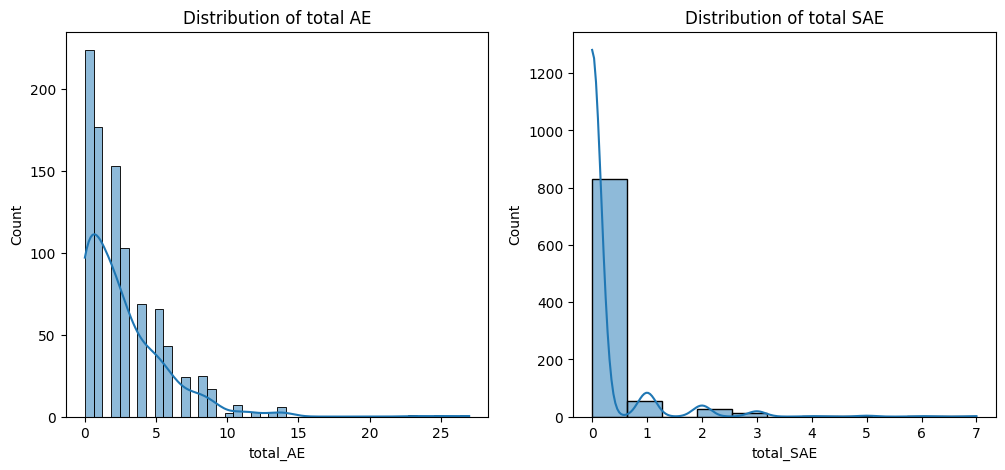

In [32]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(fin_df2['total_AE'], kde=True)
plt.title('Distribution of total AE')
plt.subplot(1, 2, 2)
sns.histplot(fin_df2['total_SAE'], kde=True)
plt.title('Distribution of total SAE')
plt.show()

In [33]:
X2 = fin_df2.drop(['total_AE', 'total_SAE'], axis=1)
y2_ae = fin_df2['total_AE']
y2_sae = fin_df2['total_SAE']

In [34]:
scaler = StandardScaler()
X_scaled2 = scaler.fit_transform(X2)
X_scaled2 = pd.DataFrame(X_scaled2, columns=X2.columns)

In [36]:
# For total_AE
rf_ae = RandomForestRegressor(n_estimators=250,max_depth= 6, random_state=42)
rf_ae.fit(X_scaled2, y2_ae)
feature_importance_ae = pd.DataFrame({'feature': X2.columns, 'importance': rf_ae.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)

# For total_SAE
rf_sae = RandomForestRegressor(n_estimators=250,max_depth= 6,random_state=42)
rf_sae.fit(X_scaled2, y2_sae)
feature_importance_sae = pd.DataFrame({'feature': X2.columns, 'importance': rf_sae.feature_importances_})
feature_importance_sae = feature_importance_sae.sort_values('importance', ascending=False)

print("Top features for total_AE:")
print(feature_importance_ae.head(30))
print("\nTop features for total_SAE:")
print(feature_importance_sae.head(30))

Top features for total_AE:
                feature  importance
170             AERELCM    0.469273
172             AEACT03    0.340588
166  prior_chemo_cycles    0.046243
169               AEREL    0.018071
177            AEFIWDOS    0.015800
175            AEIRWDOS    0.010127
178            AEFICDOS    0.008964
185           month1_AE    0.007963
176            AEIRCDOS    0.007016
180            AEFBCDOS    0.005660
23             B_HEIGHT    0.005332
0                SUBJID    0.004886
179            AEFBWDOS    0.004079
21               TRTDUR    0.003984
14              B_LDHNM    0.002803
1                   AGE    0.002795
22             B_WEIGHT    0.002749
30             BIOPTPCT    0.002597
181            AELLWDOS    0.002390
24                B_BSA    0.002219
49              biopdy2    0.001951
46               diagdy    0.001830
25             DIAGMONS    0.001760
8              B_METANM    0.001513
182            AELLCDOS    0.001490
184            AEDLCDOS    0.001304
4

In [37]:
top_features_ae = feature_importance_ae['feature'][:30].tolist()
top_features_sae = feature_importance_sae['feature'][:30].tolist()

In [38]:
X_ae = X_scaled2[top_features_ae]
X_sae = X_scaled2[top_features_sae]
# Split the data into train, validation, and test sets
X_train, X_temp, y_ae_train, y_ae_temp = train_test_split(X_ae, y2_ae, test_size=0.33, random_state=42)
X_val, X_test, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.3, random_state=42)

X_train, X_temp, y_sae_train, y_sae_temp = train_test_split(X_sae, y2_sae, test_size=0.33, random_state=42)
X_val, X_test, y_sae_val, y_sae_test = train_test_split(X_temp, y_sae_temp, test_size=0.3, random_state=42)

In [40]:
# from sklearn.model_selection import RandomizedSearchCV
# from scipy.stats import uniform, randint

# param_distributions = {
#     'n_estimators': randint(50, 500),
#     'learning_rate': uniform(0.01, 0.3),
#     'max_depth': randint(3, 10),
#     'subsample': uniform(0.6, 0.4),
#     'colsample_bytree': uniform(0.6, 0.4)
# }
# random_state=42
# xgb = XGBRegressor(random_state=random_state)
# random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
# random_search.fit(X_train, y_ae_train)

# best_params = random_search.best_params_
# best_model = random_search.best_estimator_

In [45]:
# best_params

XGBoost RMSE for AE: 1.1266942702641716


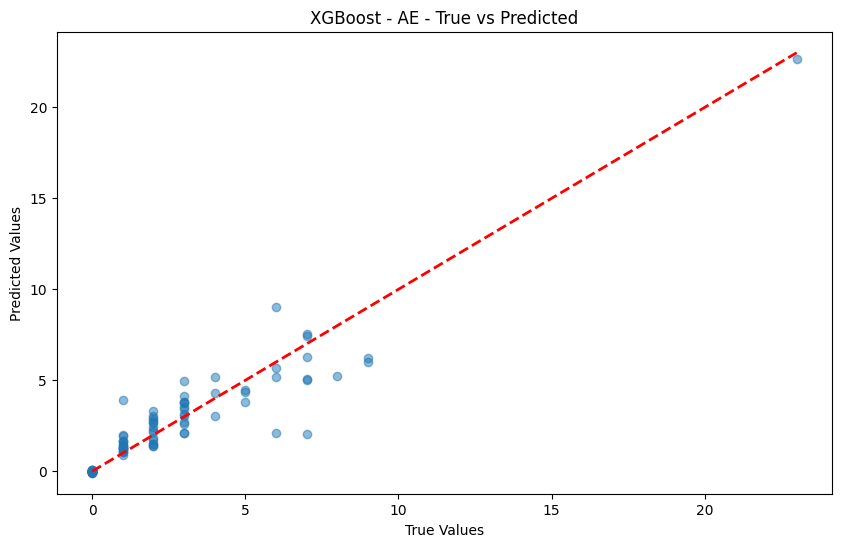

XGBoost Training RMSE: 0.015232066905123305
XGBoost Test RMSE: 1.1266942702641716
XGBoost RMSE for SAE: 0.43231859719407


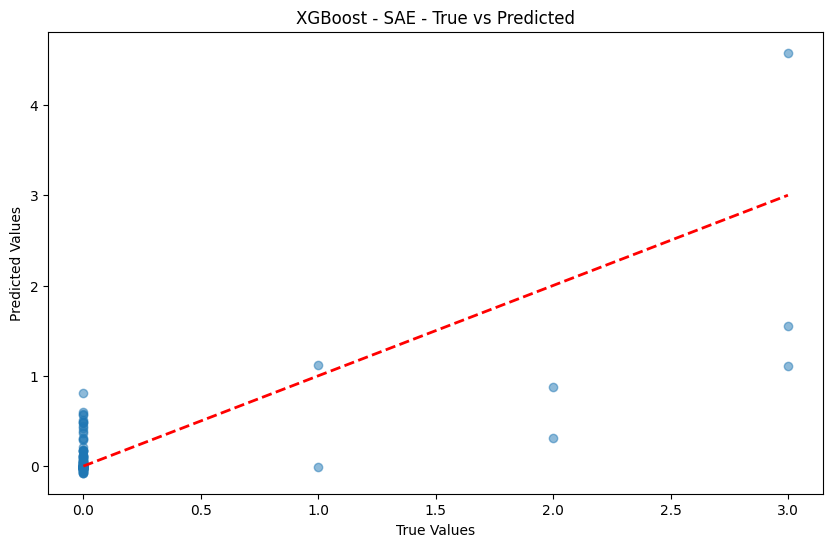

XGBoost Training RMSE: 0.0044225526240605564
XGBoost Test RMSE: 0.43231859719407


In [43]:
# XGBoost
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=279,
        learning_rate=0.083,
        eta=0.1,
        max_depth=6,
        random_state=42,
        eval_metric='rmse',
        subsample=0.7572,
        colsample_bytree=0.7060,
        gamma=0
    ),
    X_train, y_ae_train, X_val, y_ae_val, X_test, y_ae_test, "XGBoost", "AE"
)

xgb_sae, xgb_sae_comparison, train_sae_mse, test_sae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=279,
        learning_rate=0.083,
        eta=0.1,
        max_depth=6,
        random_state=42,
        eval_metric='rmse',
        subsample=0.7572,
        colsample_bytree=0.7060,
        gamma=0
    ),
    X_train, y_sae_train, X_val, y_sae_val, X_test, y_sae_test, "XGBoost", "SAE"
)

In [44]:
#for AE
xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
xgb_sae_comparison['Predicted'] = np.round(xgb_sae_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)
print("")
#for SAE
compdf_xgb_sae= pd.DataFrame({'actual_SAE': xgb_sae_comparison['Actual'].values, 'predicted_SAE': [round(i) for i in xgb_sae_comparison['Predicted']]})
diff_xgb_sae = abs(compdf_xgb_sae['actual_SAE']-compdf_xgb_sae['predicted_SAE'])
print("sum of absolute diff between predicted and actual SAE: ",diff_xgb_sae.sum())
print("max value abs diff in SAE: ",max(diff_xgb_sae))
average_deviation_sae = sum(diff_xgb_sae) / len(diff_xgb_sae)
print("average deviation in predicted and actual SAE: ",average_deviation_sae)

sum of absolute diff between predicted and actual AE:  59
max value abs diff in AE:  5
average deviation in predicted and actual AE:  0.6413043478260869

sum of absolute diff between predicted and actual SAE:  14
max value abs diff in SAE:  2
average deviation in predicted and actual SAE:  0.15217391304347827


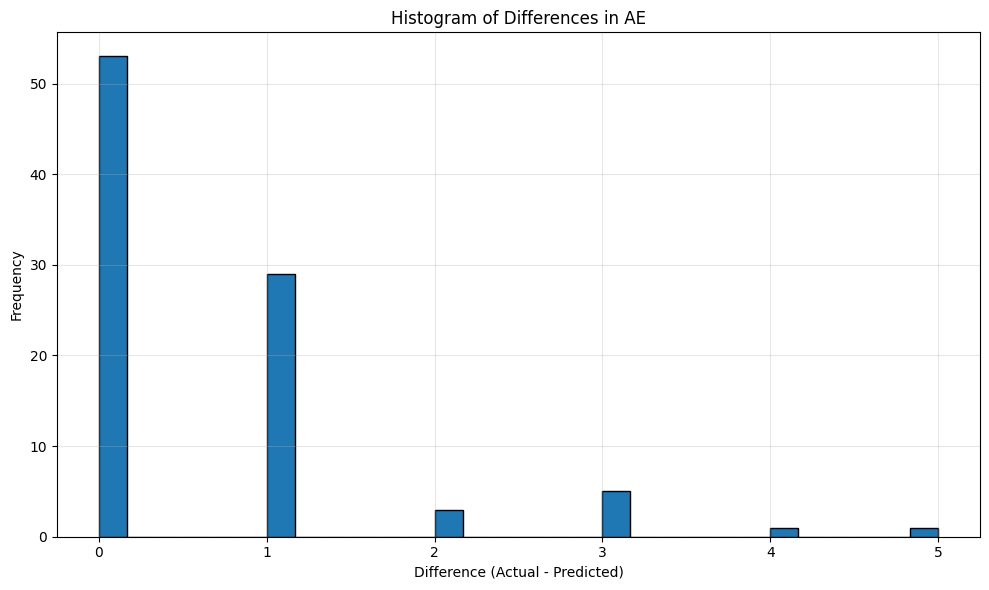

In [46]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

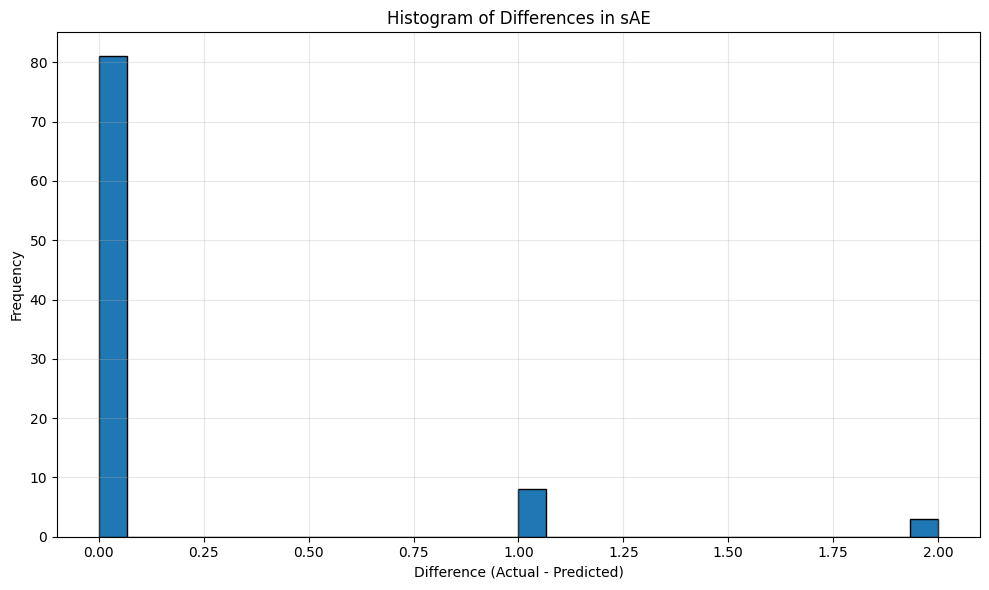

In [47]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb_sae, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in sAE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Month>=3

In [48]:
# Group by SUBJID and sum total_AE and total_SAE for all months except 1 and 2
m3_ae = ae_data[~ae_data['ae_month'].isin(['month1', 'month2'])].groupby('SUBJID').agg({
    'total_AE': 'sum',
    'total_SAE': 'sum'
})

# Get one row per SUBJID with all other columns (except ae_month)
other_columns = ae_data.drop(['ae_month', 'total_AE', 'total_SAE'], axis=1).drop_duplicates(subset=['SUBJID'])

# Merge the summed totals with the other columns
m3_ae = other_columns.merge(m3_ae, on='SUBJID', how='left')

In [49]:
fin_df3 = pd.merge(demobl,medhist,on=['SUBJID'],how='left')
fin_df3 = pd.merge(fin_df3,m3_ae,on=['SUBJID'],how='inner')
fin_df3.columns = fin_df3.columns.str.replace(" ", "_")
fin_df3.columns = fin_df3.columns.str.replace("<", "lessthan")
fin_df3.drop(columns=['BIOPF', 'BIOPHF', 'BIOPRS', 'BIOPEF'],inplace=True)

fin_df3.head()

,Unnamed:_0,SUBJID,AGE,TRTDOSE,PRBEVR,PRBEVM,PRBEVCD,PROXAR,PROXAM,B_METANM,LIVRONLY,PRADJYN,DPADJUV,B_LDHYN,B_LDH2YN,B_LDHNM,TUMCAT,LIVERMET,EVALITT,EVALPP,EVALQOL,EVALEGFR,TRTDUR,B_WEIGHT,B_HEIGHT,B_BSA,DIAGMONS,METMONS,BIOPACPT,BIOPHACT,BIOPSTCD,BIOPTPCT,BIOPRSCD,BIOPNEG,BIOPWEAK,BIOPMOD,BIOPSTRG,BIOP3,BIOPS123,BIOPCYTO,H11NEG,H11WEAK,H11MOD,UGT1A1YN,CHILDPOT,PREGDONE,BIONANY,diagdy,metdxdy,biopdy,biopdy2,PREGDY,HDIFFER_Poorly_differentiated,HDIFFER_Undifferentiated,HDIFFER_Unknown,HDIFFER_Well_differentiated,HISSUBTY_Mucinous,HISSUBTY_No_sub-type,HISSUBTY_Other,HISSUBTY_Unknown,BIOPNO_100-500_cells_present,BIOPNO_50-99_cells_present,BIOPNO_>500_cells_present,BIOPPCT_lessthan10%,BIOPPCT_>35%,BIOPCY_lessthan10%,BIOPCY_>35%,BIOPMAX_1+,BIOPMAX_2+,BIOPMAX_3+,BIOPSITE_Primary,B_ECOG_In_bed,B_ECOG_Symptoms_but_ambulatory,PREGRES_Not_applicable,SEX_Female,SEX_Male,RACCAT_Other,RACCAT_White_or_Caucasian,ATRT_FOLFIRI_alone,ATRT_Panitumumab_+_FOLFIRI,PRBEV_N,PRBEV_Y,PROXAL_N,PROXAL_Y,B_METACT_1,B_METACT_2,B_METACT_>=3,B_ECOGI_Fully_active,B_ECOGI_In_bed_less_than_50%_of_the_time,B_ECOGI_Symptoms_but_ambulatory,BECGICT_0_or_1,BECGICT_2,DIAGTYPE_Colon,DIAGTYPE_Rectal,KRAS_Failed,KRAS_Mutant,KRAS_Wild-type,BIOPMAXC_0,BIOPMAXC_1+,BIOPMAXC_2+,BIOPMAXC_3+,BIOPBSIT_Anus,BIOPBSIT_Bone,BIOPBSIT_Breast,BIOPBSIT_Colon,BIOPBSIT_Liver,BIOPBSIT_Lung_parenchyma,BIOPBSIT_Lymph_Nodes,BIOPBSIT_Other,BIOPBSIT_Peritoneum,BIOPBSIT_Pleural_effusion,BIOPBSIT_Rectum,BIOPBSIT_Small_Intestine,BIOPBSIT_Stomach,PREGTYPE_Pregnancy_-_Serum,PREGTYPE_Pregnancy_-_Urine,MHANY,MHBNGNYN,MHBODSYS_Dermatologic,MHBODSYS_Endocrine/Metabolic,MHBODSYS_Gastrointestinal,MHBODSYS_Genitourinary/Reproductive,MHBODSYS_Hematologic/Lymphatic,MHBODSYS_Hepatic/Biliary,MHBODSYS_Immunologic,MHBODSYS_Musculoskeletal,MHBODSYS_Neurologic,MHBODSYS_Other,MHBODSYS_Psychiatric,MHBODSYS_Renal,MHBODSYS_Respiratory,MHBODSYS_Special_Senses,MHCOND_Benign_bone_lesions,MHCOND_Benign_liver_lesions,MHCOND_Benign_lung_lesions,MHCOND_Benign_mediastinal_and_hilar_masses/nodules,MHCOND_Benign_renal_lesions,MHCOND_Benign_retroperitoneal_abnormalities,MHCOND_Other,"MHCOND_Post-surgical._-procedural,_or_-inflammatory_fibrosis_or_scarring",MHCOND_Post-traumatic_hematomas,MHSITE_Ascites,MHSITE_Bone,MHSITE_Brain,MHSITE_Breast,MHSITE_Chest_wall,MHSITE_Colon,MHSITE_Esophagus,MHSITE_Gall_bladder,MHSITE_Kidney,MHSITE_Liver,MHSITE_Lung_parenchyma,MHSITE_Lymph_Nodes,MHSITE_Other,MHSITE_Pancreas,MHSITE_Pelvis,MHSITE_Pericardial_Effusion,MHSITE_Peritoneum,MHSITE_Pleura_or_pleural_wall,MHSITE_Rectum,MHSITE_Skin,MHSITE_Small_Intestine,MHSITE_Spinal_cord,MHSITE_Spleen,MHSITE_Thyroid,MHSTAT_Resolved,prior_infusions,prior_chemo_cycles,prior_to_investigation,intermittent,AEREL,AERELCM,AEINFCTC,AEACT03,AEWDOS,AECDOS,AEIRWDOS,AEIRCDOS,AEFIWDOS,AEFICDOS,AEFBWDOS,AEFBCDOS,AELLWDOS,AELLCDOS,AEDLWDOS,AEDLCDOS,total_AE,total_SAE
0,0,201001001,54.0,6.0,1,1,1.0,1,1,4.0,0,0,0.0,0.0,0.0,187.0,1,1,1,1,1,1,219.0,80.0,182.0,2.011080,9.540984,9.540984,1.0,1.0,1.0,61.28,1.0,85.3,9.8,5.0,0.0,0.0,14.8,2.1,97.9,2.1,0.0,0.0,0.0,0.0,0.0,-293.0,-293.0,644.0,667.0,0.0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,1.0,0.0,1.0,2,1.0,0,1,6.000000,6.000000,179.903298,179.903298,2398.710643,2398.710643,399.785107,399.785107,0.0,0.0,399.785107,399.785107,2,0
1,1,201001002,66.0,6.0,1,1,1.0,1,1,3.0,0,0,0.0,0.0,0.0,215.0,1,1,1,1,1,1,60.0,93.0,178.0,2.144372,6.131148,6.131148,1.0,1.0,1.0,43.22,1.0,99.9,0.1,0.0,0.0,0.0,0.1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,-193.0,-193.0,670.0,698.0,0.0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,0,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3.0,3.0,0.0,0.0,2,0.0,0,2,6.000000,18.000000,177.226673,531.680019,2

In [50]:
X2 = fin_df2[['SUBJID','total_AE','total_SAE']]
X2.rename(columns={'total_AE': 'month2_AE', 'total_SAE': 'month2_SAE'}, inplace=True)
X2

<ipython-input-50-35125ef67af6>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X2.rename(columns={'total_AE': 'month2_AE', 'total_SAE': 'month2_SAE'}, inplace=True)


,SUBJID,month2_AE,month2_SAE
0,201001001,0,0
1,201001002,0,0
2,201001004,2,0
3,201001005,1,0
4,201001006,0,0
...,...,...,...
920,203906002,0,0
921,203906003,3,0
922,203906005,0,0
923,203906006,0,0


In [51]:
fin_df3 = pd.merge(fin_df3,X2,on=['SUBJID'],how='left')
print(fin_df3)

     Unnamed:_0     SUBJID   AGE  TRTDOSE  PRBEVR  PRBEVM  PRBEVCD  PROXAR  PROXAM  B_METANM  LIVRONLY  PRADJYN  DPADJUV  B_LDHYN  B_LDH2YN  B_LDHNM  TUMCAT  LIVERMET  EVALITT  EVALPP  EVALQOL  EVALEGFR  TRTDUR  B_WEIGHT  B_HEIGHT     B_BSA   DIAGMONS    METMONS  BIOPACPT  BIOPHACT  BIOPSTCD  BIOPTPCT  BIOPRSCD  BIOPNEG  BIOPWEAK  BIOPMOD  BIOPSTRG  BIOP3  BIOPS123  BIOPCYTO  H11NEG  H11WEAK  H11MOD  UGT1A1YN  CHILDPOT  PREGDONE  BIONANY  diagdy  metdxdy  biopdy  biopdy2  PREGDY  HDIFFER_Poorly_differentiated  HDIFFER_Undifferentiated  HDIFFER_Unknown  HDIFFER_Well_differentiated  HISSUBTY_Mucinous  HISSUBTY_No_sub-type  HISSUBTY_Other  HISSUBTY_Unknown  BIOPNO_100-500_cells_present  BIOPNO_50-99_cells_present  BIOPNO_>500_cells_present  BIOPPCT_lessthan10%  BIOPPCT_>35%  BIOPCY_lessthan10%  BIOPCY_>35%  BIOPMAX_1+  BIOPMAX_2+  BIOPMAX_3+  BIOPSITE_Primary  B_ECOG_In_bed  B_ECOG_Symptoms_but_ambulatory  PREGRES_Not_applicable  SEX_Female  SEX_Male  RACCAT_Other  \
0             0  2010

In [52]:
fin_df3.drop(columns=['Unnamed:_0'],inplace=True)

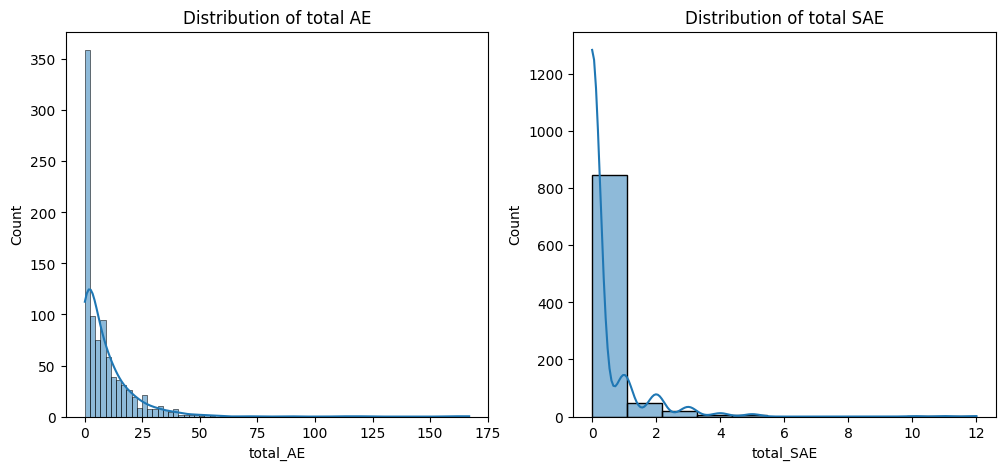

In [53]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(fin_df3['total_AE'], kde=True)
plt.title('Distribution of total AE')
plt.subplot(1, 2, 2)
sns.histplot(fin_df3['total_SAE'], kde=True)
plt.title('Distribution of total SAE')
plt.show()

In [54]:
X3 = fin_df3.drop(['total_AE', 'total_SAE'], axis=1)
y3_ae = fin_df3['total_AE']
y3_sae = fin_df3['total_SAE']

In [55]:
scaler = StandardScaler()
X_scaled3 = scaler.fit_transform(X3)
X_scaled3 = pd.DataFrame(X_scaled3, columns=X3.columns)

In [56]:
# For total_AE
rf_ae = RandomForestRegressor(n_estimators=100,max_depth= 5, random_state=42)
rf_ae.fit(X_scaled3, y3_ae)
feature_importance_ae = pd.DataFrame({'feature': X3.columns, 'importance': rf_ae.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)

# For total_SAE
rf_sae = RandomForestRegressor(n_estimators=100,max_depth= 5,random_state=42)
rf_sae.fit(X_scaled3, y3_sae)
feature_importance_sae = pd.DataFrame({'feature': X3.columns, 'importance': rf_sae.feature_importances_})
feature_importance_sae = feature_importance_sae.sort_values('importance', ascending=False)

print("Top features for total_AE:")
print(feature_importance_ae.head(30))
print("\nTop features for total_SAE:")
print(feature_importance_sae.head(30))

Top features for total_AE:
                        feature  importance
21                       TRTDUR    0.493155
185                   month2_AE    0.129848
0                        SUBJID    0.071825
170                     AERELCM    0.062762
169                       AEREL    0.022133
183                    AEDLWDOS    0.016660
172                     AEACT03    0.015716
181                    AELLWDOS    0.011663
49                      biopdy2    0.010209
22                     B_WEIGHT    0.009054
48                       biopdy    0.008076
182                    AELLCDOS    0.008016
27                     BIOPACPT    0.007943
1                           AGE    0.007781
168                intermittent    0.007401
177                    AEFIWDOS    0.006685
175                    AEIRWDOS    0.006617
173                      AEWDOS    0.005814
178                    AEFICDOS    0.005214
23                     B_HEIGHT    0.004979
174                      AECDOS    0.004662
113  

In [57]:
top_features_ae = feature_importance_ae['feature'][:30].tolist()
top_features_sae = feature_importance_sae['feature'][:30].tolist()

In [58]:
X_ae = X_scaled3[top_features_ae]
X_sae = X_scaled3[top_features_sae]
# Split the data into train, validation, and test sets
X_train, X_temp, y_ae_train, y_ae_temp = train_test_split(X_ae, y3_ae, test_size=0.33, random_state=42)
X_val, X_test, y_ae_val, y_ae_test = train_test_split(X_temp, y_ae_temp, test_size=0.3, random_state=42)

X_train, X_temp, y_sae_train, y_sae_temp = train_test_split(X_sae, y3_sae, test_size=0.33, random_state=42)
X_val, X_test, y_sae_val, y_sae_test = train_test_split(X_temp, y_sae_temp, test_size=0.3, random_state=42)

In [67]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_distributions = {
    'n_estimators': randint(50, 500),
    'learning_rate': uniform(0.01, 0.3),
    'max_depth': randint(3, 10),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4)
}
random_state=42
xgb = XGBRegressor(random_state=random_state)
random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=100, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=random_state)
random_search.fit(X_train, y_ae_train)

best_params = random_search.best_params_
best_model = random_search.best_estimator_

In [68]:
best_params

{'colsample_bytree': 0.9849789179768444,
 'learning_rate': 0.08553468874760924,
 'max_depth': 4,
 'n_estimators': 436,
 'subsample': 0.7203513239267079}

XGBoost RMSE for AE: 8.664926676785838


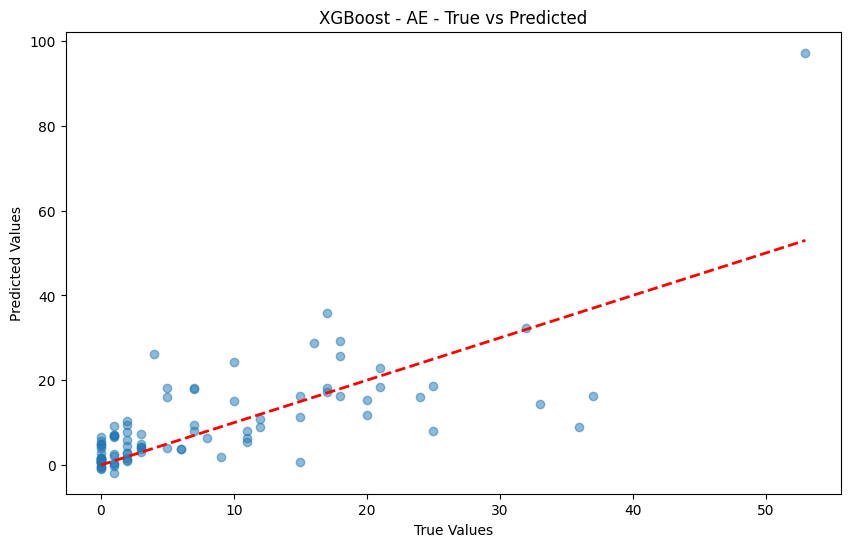

XGBoost Training RMSE: 0.3891570782517556
XGBoost Test RMSE: 8.664926676785838
XGBoost RMSE for SAE: 0.7557596101654971


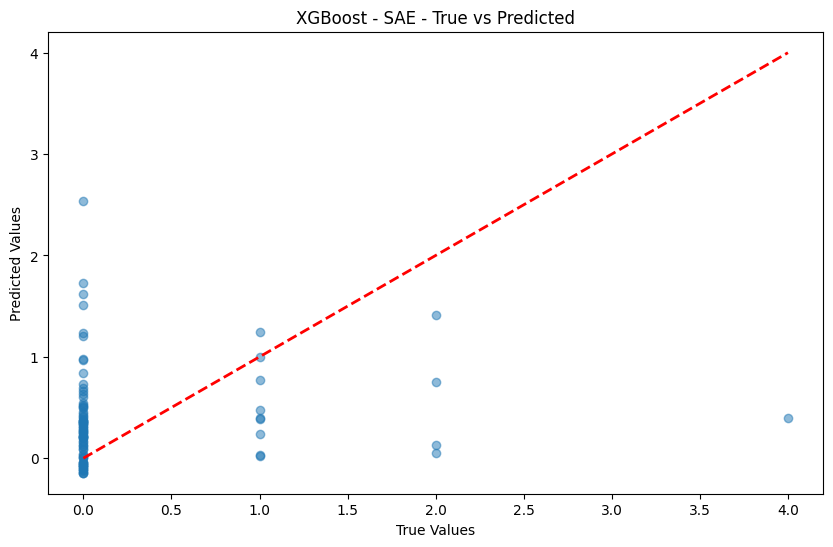

XGBoost Training RMSE: 0.05391968137938192
XGBoost Test RMSE: 0.7557596101654971


In [59]:
# XGBoost
xgb_ae, xgb_ae_comparison, train_ae_mse, test_ae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=436,
        learning_rate=0.0855,
        eta=0.1,
        max_depth=4,
        random_state=42,
        eval_metric='rmse',
        subsample=0.7210,
        colsample_bytree=0.9850,
        gamma=0
    ),
    X_train, y_ae_train, X_val, y_ae_val, X_test, y_ae_test, "XGBoost", "AE"
)

xgb_sae, xgb_sae_comparison, train_sae_mse, test_sae_mse = train_and_evaluate(
    XGBRegressor(
        n_estimators=436,
        learning_rate=0.0855,
        eta=0.1,
        max_depth=4,
        random_state=42,
        eval_metric='rmse',
        subsample=0.7210,
        colsample_bytree=0.9850,
        gamma=0
    ),
    X_train, y_sae_train, X_val, y_sae_val, X_test, y_sae_test, "XGBoost", "SAE"
)

In [60]:
#for AE
xgb_ae_comparison['Predicted'] = np.round(xgb_ae_comparison['Predicted'])
xgb_sae_comparison['Predicted'] = np.round(xgb_sae_comparison['Predicted'])
compdf_xgb= pd.DataFrame({'actual_AE': xgb_ae_comparison['Actual'].values, 'predicted_AE': [round(i) for i in xgb_ae_comparison['Predicted']]})
diff_xgb = abs(compdf_xgb['actual_AE']-compdf_xgb['predicted_AE'])
print("sum of absolute diff between predicted and actual AE: ",diff_xgb.sum())
print("max value abs diff in AE: ",max(diff_xgb))
# count=0
# for i in range(len(diff_xgb)):
#   if diff_xgb[i]>0:
#     count+=1
# print("count of values that diff ",count)
average_deviation = sum(diff_xgb) / len(diff_xgb)
print("average deviation in predicted and actual AE: ",average_deviation)
print("")
#for SAE
compdf_xgb_sae= pd.DataFrame({'actual_SAE': xgb_sae_comparison['Actual'].values, 'predicted_SAE': [round(i) for i in xgb_sae_comparison['Predicted']]})
diff_xgb_sae = abs(compdf_xgb_sae['actual_SAE']-compdf_xgb_sae['predicted_SAE'])
print("sum of absolute diff between predicted and actual SAE: ",diff_xgb_sae.sum())
print("max value abs diff in SAE: ",max(diff_xgb_sae))
average_deviation_sae = sum(diff_xgb_sae) / len(diff_xgb_sae)
print("average deviation in predicted and actual SAE: ",average_deviation_sae)

sum of absolute diff between predicted and actual AE:  490
max value abs diff in AE:  44
average deviation in predicted and actual AE:  5.326086956521739

sum of absolute diff between predicted and actual SAE:  39
max value abs diff in SAE:  4
average deviation in predicted and actual SAE:  0.42391304347826086


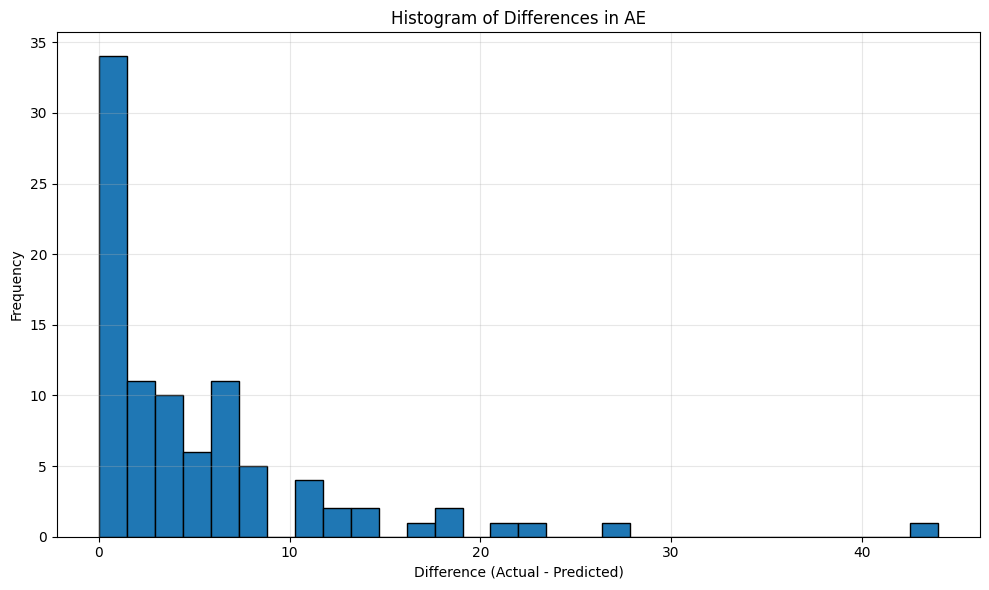

In [61]:
plt.figure(figsize=(10, 6))
plt.hist(diff_xgb, bins=30, edgecolor='black')
plt.xlabel('Difference (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Histogram of Differences in AE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
# print(sum(y_ae_test)/len(y_ae_test))

# with manual feature engineering